In [2]:
%%capture
!pip uninstall -y numpy scipy albumentations
!pip install numpy==2.0.2 scipy==1.16.1 albumentations==2.0.8
!pip install segmentation-models-pytorch timm pretrainedmodels


In [3]:
import os
import torch
import torch.nn as nn
import cv2
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
import matplotlib.pyplot as plt
from tqdm import tqdm
import time
import json

print("✅ Libraries installed and imported.")

/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

✅ Libraries installed and imported.


In [4]:
# ============================================================================
# CONFIGURATION
# ============================================================================
class Config:
    DATASET_PATH = "/kaggle/input/culane/CULane"
    # Ensure these paths match your uploaded models
    MODEL1_PATH = "/kaggle/input/culane-model/pytorch/default/1/best_deeplabv3plus_culane.pth"  
    MODEL2_PATH = "/kaggle/input/trainned-model-culane/pytorch/default/1/best_shadow_night_model.pth"  
    
    BATCH_SIZE = 16
    IMG_HEIGHT = 288
    IMG_WIDTH = 800
    NUM_CLASSES = 9
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    NUM_WORKERS = 2
    
    # Ensemble settings
    ENSEMBLE_METHOD = 'average'
    ENSEMBLE_WEIGHTS = [0.5, 0.5]

config = Config()
print(f"✓ Device: {config.DEVICE}")
print(f"✓ Configuration loaded")

✓ Device: cuda
✓ Configuration loaded


In [5]:
# ============================================================================
# DATA TRANSFORMS
# ============================================================================
val_transform = A.Compose([
    A.Resize(config.IMG_HEIGHT, config.IMG_WIDTH),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

# ============================================================================
# DATASET CLASSES
# ============================================================================
from torch.utils.data import Dataset, DataLoader

class CULaneDataset(Dataset):
    def __init__(self, dataset_path, split='val', transform=None):
        self.dataset_path = dataset_path
        self.transform = transform
        
        list_file = os.path.join(dataset_path, 'list', 'list', f'{split}.txt')
        with open(list_file, 'r') as f:
            self.samples = [line.strip().split()[0] for line in f.readlines()]
        
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_name = self.samples[idx].lstrip('/')
        driver_folder = img_name.split('/')[0]
        img_path = os.path.join(self.dataset_path, driver_folder, img_name)
        
        relative_path = '/'.join(img_name.split('/')[1:])
        label_path = os.path.join(self.dataset_path, 'laneseg_label_w16', 
                                  'laneseg_label_w16', driver_folder, relative_path)
        label_path = label_path.replace('.jpg', '.png')
        
        image = cv2.imread(img_path)
        if image is None: raise FileNotFoundError(f"Image not found: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        label = cv2.imread(label_path, cv2.IMREAD_GRAYSCALE)
        if label is None: raise FileNotFoundError(f"Label not found: {label_path}")
        
        if self.transform:
            transformed = self.transform(image=image, mask=label)
            image = transformed['image']
            label = transformed['mask']
        
        return image, label.long()

class CULaneTestDataset(Dataset):
    def __init__(self, dataset_path, scenario_file, transform=None):
        self.dataset_path = dataset_path
        self.transform = transform
        list_file = os.path.join(dataset_path, 'list', 'list', scenario_file)
        with open(list_file, 'r') as f:
            self.samples = [line.strip().split()[0] for line in f.readlines()]
            
    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        img_name = self.samples[idx].lstrip('/')
        driver_folder = img_name.split('/')[0]
        img_path = os.path.join(self.dataset_path, driver_folder, img_name)
        
        relative_path = '/'.join(img_name.split('/')[1:])
        label_path = os.path.join(self.dataset_path, 'laneseg_label_w16_test', 
                                  'laneseg_label_w16_test', driver_folder, relative_path)
        label_path = label_path.replace('.jpg', '.png')
        
        image = cv2.imread(img_path)
        if image is None: raise FileNotFoundError(f"Image not found: {img_path}")
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        label = cv2.imread(label_path, cv2.IMREAD_GRAYSCALE)
        if label is None: label = np.zeros((image.shape[0], image.shape[1]), dtype=np.uint8)
        
        if self.transform:
            transformed = self.transform(image=image, mask=label)
            image = transformed['image']
            label = transformed['mask']
        return image, label.long()

print("✓ Dataset classes defined")

✓ Dataset classes defined


In [6]:
# ============================================================================
# LOAD TRAINED MODELS
# ============================================================================
print("⏳ Loading models...")

# Model 1: General (Full Dataset)
model1 = smp.DeepLabV3Plus(encoder_name="resnet50", encoder_weights=None, in_channels=3, classes=config.NUM_CLASSES)
checkpoint1 = torch.load(config.MODEL1_PATH, map_location=config.DEVICE)
model1.load_state_dict(checkpoint1['model_state_dict'])
model1.to(config.DEVICE).eval()
print("✅ Model 1 (General) loaded")

# Model 2: Specialist (Shadow/Night)
model2 = smp.DeepLabV3Plus(encoder_name="resnet50", encoder_weights=None, in_channels=3, classes=config.NUM_CLASSES)
checkpoint2 = torch.load(config.MODEL2_PATH, map_location=config.DEVICE)
model2.load_state_dict(checkpoint2['model_state_dict'])
model2.to(config.DEVICE).eval()
print("✅ Model 2 (Specialist) loaded")

# ============================================================================
# ENSEMBLE PREDICTOR
# ============================================================================
class EnsemblePredictor:
    def __init__(self, models, method='average', weights=None):
        self.models = models
        self.method = method
        self.weights = weights if weights else [1.0/len(models)] * len(models)
        
    def predict(self, images):
        outputs = []
        with torch.no_grad():
            for model in self.models:
                output = model(images)
                outputs.append(output)
        
        if self.method == 'average':
            ensemble_logits = sum(w * out for w, out in zip(self.weights, outputs))
            predictions = torch.argmax(ensemble_logits, dim=1)
            probabilities = torch.softmax(ensemble_logits, dim=1)
            
        return predictions, probabilities

ensemble_predictor = EnsemblePredictor(
    models=[model1, model2],
    method=config.ENSEMBLE_METHOD,
    weights=config.ENSEMBLE_WEIGHTS
)
print("✓ Ensemble predictor ready")

⏳ Loading models...
✅ Model 1 (General) loaded
✅ Model 2 (Specialist) loaded
✓ Ensemble predictor ready


In [7]:
# ==========================================
# STEP 6: Evaluation Metrics Functions
# ==========================================
def calculate_detailed_metrics(ensemble_predictor, loader, device, num_classes=5):
    """Calculate comprehensive metrics"""
    
    total_correct = 0
    total_pixels = 0
    
    tp = torch.zeros(num_classes)
    fp = torch.zeros(num_classes)
    fn = torch.zeros(num_classes)
    tn = torch.zeros(num_classes)
    
    for images, masks in tqdm(loader, desc='Calculating Metrics'):
        images = images.to(device)
        masks = masks.to(device)
        
        preds, _ = ensemble_predictor.predict(images)
        
        total_correct += (preds == masks).sum().item()
        total_pixels += masks.numel()
        
        for cls in range(num_classes):
            pred_cls = (preds == cls)
            mask_cls = (masks == cls)
            
            tp[cls] += (pred_cls & mask_cls).sum().item()
            fp[cls] += (pred_cls & ~mask_cls).sum().item()
            fn[cls] += (~pred_cls & mask_cls).sum().item()
            tn[cls] += (~pred_cls & ~mask_cls).sum().item()
    
    pixel_accuracy = total_correct / total_pixels
    class_accuracy = (tp + tn) / (tp + tn + fp + fn + 1e-10)
    
    precision = tp / (tp + fp + 1e-10)
    recall = tp / (tp + fn + 1e-10)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-10)
    iou = tp / (tp + fp + fn + 1e-10)
    
    print(f"\n{'='*80}")
    print("ENSEMBLE MODEL - DETAILED METRICS")
    print('='*80)
    print(f"\n📊 Overall Pixel Accuracy: {pixel_accuracy*100:.2f}%")
    
    class_names = ['Background', 'Lane1', 'Lane2', 'Lane3', 'Lane4']
    
    print(f"\n{'Class':<12} {'Acc':<8} {'Prec':<8} {'Recall':<8} {'F1':<8} {'IoU':<8}")
    print('-'*70)
    
    for cls in range(num_classes):
        print(f"{class_names[cls]:<12} "
              f"{class_accuracy[cls]*100:>6.2f}%  "
              f"{precision[cls]:>6.4f}  "
              f"{recall[cls]:>6.4f}  "
              f"{f1[cls]:>6.4f}  "
              f"{iou[cls]:>6.4f}")
    
    return {
        'pixel_accuracy': pixel_accuracy,
        'class_accuracy': class_accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'iou': iou
    }


# ==========================================
# Validation Evaluation
# ==========================================
print("\n" + "="*70)
print("EVALUATING ENSEMBLE ON VALIDATION SET")
print("="*70)

val_dataset = CULaneDataset(
    config.DATASET_PATH,
    split='val',
    transform=val_transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=config.BATCH_SIZE,
    shuffle=False,
    num_workers=config.NUM_WORKERS,
    pin_memory=True
)

val_metrics = calculate_detailed_metrics(
    ensemble_predictor,
    val_loader,
    config.DEVICE
)



EVALUATING ENSEMBLE ON VALIDATION SET


Calculating Metrics: 100%|██████████| 605/605 [09:46<00:00,  1.03it/s]


ENSEMBLE MODEL - DETAILED METRICS

📊 Overall Pixel Accuracy: 97.81%

Class        Acc      Prec     Recall   F1       IoU     
----------------------------------------------------------------------
Background    97.84%  0.9881  0.9894  0.9888  0.9778
Lane1         99.34%  0.6838  0.6897  0.6867  0.5229
Lane2         99.57%  0.7301  0.6868  0.7078  0.5477
Lane3         99.45%  0.7084  0.6572  0.6818  0.5172
Lane4         99.42%  0.6902  0.6691  0.6795  0.5145


In [8]:
# ==========================================
# Test Scenarios
# ==========================================
test_scenarios = {
    'normal': 'test_split/test0_normal.txt',
    'crowd': 'test_split/test1_crowd.txt',
    'hlight': 'test_split/test2_hlight.txt',
    'shadow': 'test_split/test3_shadow.txt',
    'noline': 'test_split/test4_noline.txt',
    'arrow': 'test_split/test5_arrow.txt',
    'curve': 'test_split/test6_curve.txt',
    'crossroad': 'test_split/test7_cross.txt',
    'night': 'test_split/test8_night.txt',
}


def evaluate_scenario(ensemble_predictor, dataset, device, scenario_name, batch_size=16):
    """Evaluate on a specific test scenario"""
    
    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )
    
    num_classes = 5
    intersection = torch.zeros(num_classes)
    union = torch.zeros(num_classes)
    tp = torch.zeros(num_classes)
    fp = torch.zeros(num_classes)
    fn = torch.zeros(num_classes)
    
    total_correct = 0
    total_pixels = 0
    
    for images, masks in tqdm(loader, desc=f'Evaluating {scenario_name}'):
        images = images.to(device)
        masks = masks.to(device)
        
        preds, _ = ensemble_predictor.predict(images)
        
        total_correct += (preds == masks).sum().item()
        total_pixels += masks.numel()
        
        for cls in range(num_classes):
            pred_cls = (preds == cls)
            mask_cls = (masks == cls)
            
            intersection[cls] += (pred_cls & mask_cls).sum().item()
            union[cls] += (pred_cls | mask_cls).sum().item()
            
            tp[cls] += (pred_cls & mask_cls).sum().item()
            fp[cls] += (pred_cls & ~mask_cls).sum().item()
            fn[cls] += (~pred_cls & mask_cls).sum().item()
    
    iou = intersection / (union + 1e-10)
    
    precision = tp / (tp + fp + 1e-10)
    recall = tp / (tp + fn + 1e-10)
    f1 = 2 * precision * recall / (precision + recall + 1e-10)
    
    return {
        'mean_iou': iou.mean().item(),
        'class_iou': iou,
        'pixel_accuracy': total_correct / total_pixels,
        'precision': precision.mean().item(),
        'recall': recall.mean().item(),
        'f1': f1.mean().item()
    }


# ==========================================
# Run Test Scenarios
# ==========================================
print("\n" + "="*70)
print("EVALUATING ENSEMBLE ON TEST SCENARIOS")
print("="*70)

scenario_results = {}

for scenario_name, scenario_file in test_scenarios.items():
    print(f"\n📊 Testing: {scenario_name.upper()}")
    
    test_dataset = CULaneTestDataset(
        config.DATASET_PATH,
        scenario_file,
        transform=val_transform
    )
    
    results = evaluate_scenario(
        ensemble_predictor,
        test_dataset,
        config.DEVICE,
        scenario_name
    )
    
    results['num_samples'] = len(test_dataset)
    scenario_results[scenario_name] = results
    
    print(f"Mean IoU: {results['mean_iou']:.4f}")
    print(f"Pixel Accuracy: {results['pixel_accuracy']*100:.2f}%")


# ==========================================
# Save Results to JSON
# ==========================================
complete_results = {
    'ensemble_config': {
        'method': config.ENSEMBLE_METHOD,
        'weights': config.ENSEMBLE_WEIGHTS
    },
    'validation_metrics': {
        'pixel_accuracy': float(val_metrics['pixel_accuracy']),
        'mean_precision': float(val_metrics['precision'].mean()),
        'mean_recall': float(val_metrics['recall'].mean()),
        'mean_f1': float(val_metrics['f1'].mean()),
        'mean_iou': float(val_metrics['iou'].mean())
    },
    'test_scenarios': {}
}

for name, res in scenario_results.items():
    complete_results['test_scenarios'][name] = {
        'mean_iou': float(res['mean_iou']),
        'pixel_accuracy': float(res['pixel_accuracy']),
        'precision': float(res['precision']),
        'recall': float(res['recall']),
        'f1_score': float(res['f1']),
        'num_samples': res['num_samples'],
        'class_iou': res['class_iou'].tolist()
    }

with open("ensemble_evaluation_results.json", "w") as f:
    json.dump(complete_results, f, indent=4)

print("\n✓ Results saved to 'ensemble_evaluation_results.json'")



EVALUATING ENSEMBLE ON TEST SCENARIOS

📊 Testing: NORMAL


Evaluating normal: 100%|██████████| 602/602 [09:48<00:00,  1.02it/s]


Mean IoU: 0.7147
Pixel Accuracy: 98.36%

📊 Testing: CROWD


Evaluating crowd: 100%|██████████| 508/508 [08:18<00:00,  1.02it/s]


Mean IoU: 0.5648
Pixel Accuracy: 97.49%

📊 Testing: HLIGHT


...

Mean IoU: 0.5430
Pixel Accuracy: 97.83%

📊 Testing: CROSSROAD


Evaluating crossroad: 100%|██████████| 196/196 [03:12<00:00,  1.02it/s]


Mean IoU: 0.1993
Pixel Accuracy: 99.66%

📊 Testing: NIGHT


Evaluating night: 100%|██████████| 440/440 [07:10<00:00,  1.02it/s]

Mean IoU: 0.5087
Pixel Accuracy: 97.78%

✓ Results saved to 'ensemble_evaluation_results.json'


Generating Radar Chart...


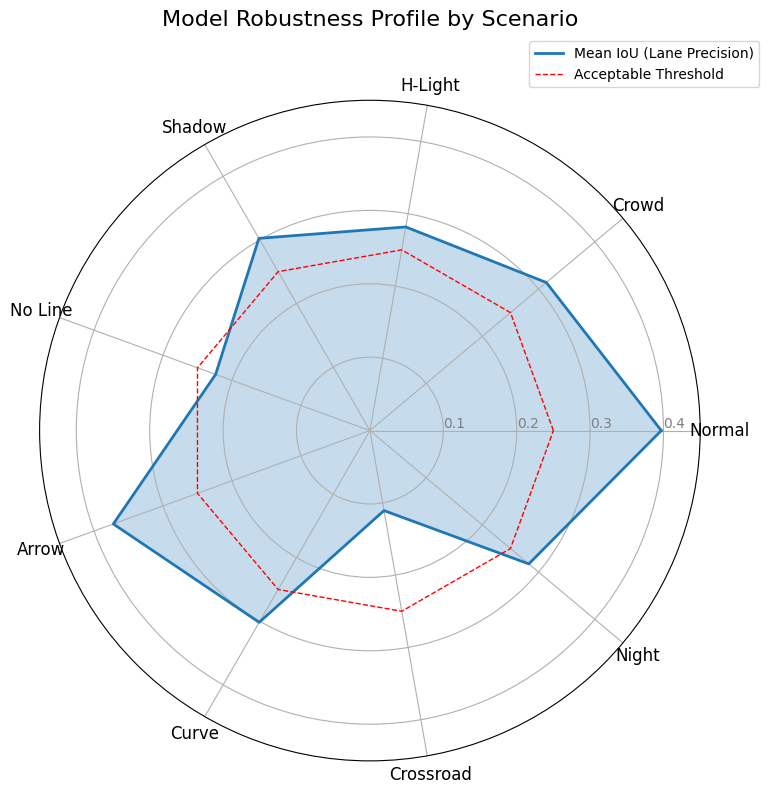

Generating Gap Analysis...


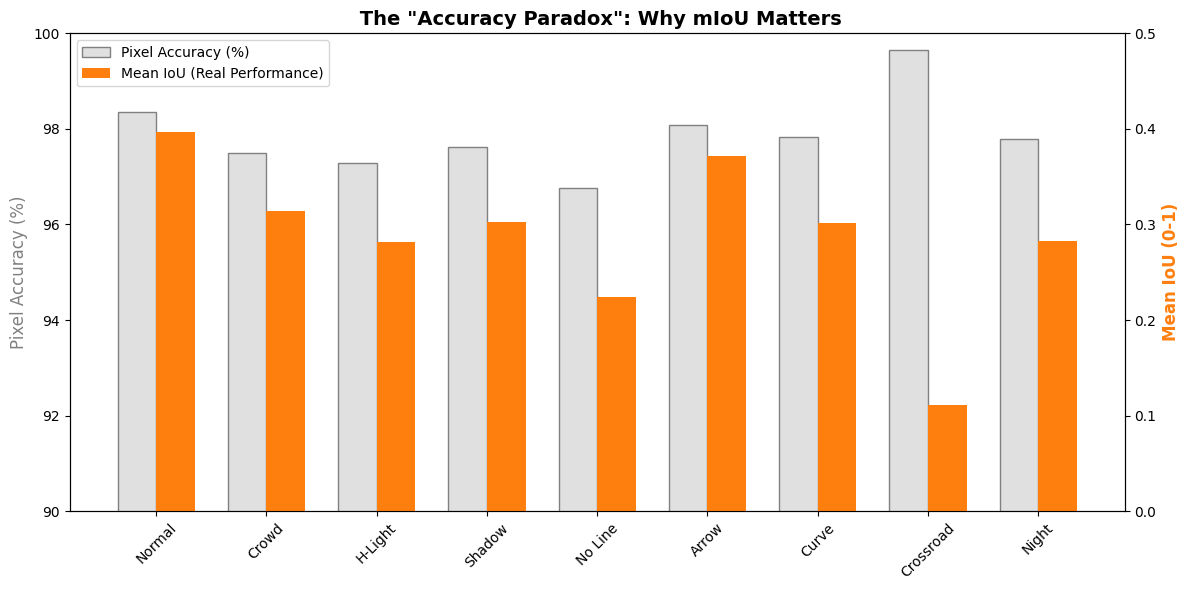

Generating Failure Mode Plot...


/tmp/ipykernel_55/2216721265.py:104: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='mIoU', y='Scenario', data=df_sorted, palette=colors)


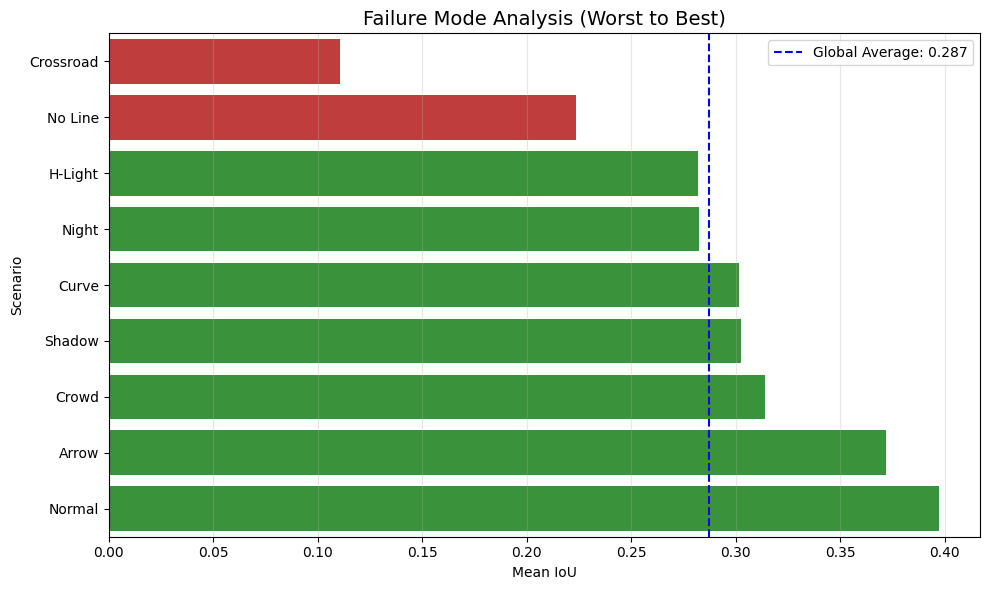

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ==========================================
# 1. PREPARE THE DATA (From your images)
# ==========================================
scenarios = ['Normal', 'Crowd', 'H-Light', 'Shadow', 'No Line', 'Arrow', 'Curve', 'Crossroad', 'Night']

# Data extracted from your uploaded graphs
miou_scores = [0.3970, 0.3138, 0.2817, 0.3024, 0.2237, 0.3720, 0.3017, 0.1107, 0.2826]
pixel_acc =   [0.9836, 0.9749, 0.9728, 0.9763, 0.9676, 0.9808, 0.9783, 0.9966, 0.9778]

# Create a DataFrame for easier plotting
df = pd.DataFrame({
    'Scenario': scenarios,
    'mIoU': miou_scores,
    'Pixel Accuracy': pixel_acc
})

# ==========================================
# 2. PLOT 1: THE RADAR CHART (Thesis Style)
# ==========================================
def plot_radar():
    # Number of variables
    N = len(scenarios)
    
    # What will be the angle of each axis in the plot?
    angles = [n / float(N) * 2 * np.pi for n in range(N)]
    angles += angles[:1] # Close the loop
    
    # Initialise the spider plot
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))
    
    # Draw one axe per variable + labels
    plt.xticks(angles[:-1], scenarios, color='black', size=12)
    
    # Draw ylabels
    ax.set_rlabel_position(0)
    plt.yticks([0.1, 0.2, 0.3, 0.4], ["0.1", "0.2", "0.3", "0.4"], color="grey", size=10)
    plt.ylim(0, 0.45)
    
    # Plot mIoU Data
    values_miou = miou_scores + miou_scores[:1]
    ax.plot(angles, values_miou, linewidth=2, linestyle='solid', label="Mean IoU (Lane Precision)", color='#1f77b4')
    ax.fill(angles, values_miou, '#1f77b4', alpha=0.25)
    
    # Add a "Threshold" line (e.g., 0.25) to show where you pass/fail
    values_thresh = [0.25] * (N + 1)
    ax.plot(angles, values_thresh, linewidth=1, linestyle='dashed', color='red', label="Acceptable Threshold")
    
    plt.title('Model Robustness Profile by Scenario', size=16, y=1.1)
    plt.legend(loc='upper right', bbox_to_anchor=(1.1, 1.1))
    plt.tight_layout()
    plt.show()

# ==========================================
# 3. PLOT 2: ACCURACY GAP ANALYSIS
# ==========================================
def plot_gap_analysis():
    fig, ax1 = plt.subplots(figsize=(12, 6))
    
    x = np.arange(len(scenarios))
    width = 0.35
    
    # Bar 1: Pixel Accuracy (High but misleading)
    rects1 = ax1.bar(x - width/2, [p*100 for p in pixel_acc], width, label='Pixel Accuracy (%)', color='#e0e0e0', edgecolor='grey')
    
    # Bar 2: Mean IoU (The real metric)
    ax2 = ax1.twinx()
    rects2 = ax2.bar(x + width/2, miou_scores, width, label='Mean IoU (Real Performance)', color='#ff7f0e')
    
    # Labels
    ax1.set_ylabel('Pixel Accuracy (%)', color='grey', fontsize=12)
    ax2.set_ylabel('Mean IoU (0-1)', color='#ff7f0e', fontsize=12, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels(scenarios, rotation=45)
    ax1.set_ylim(90, 100) # Zoom in on high accuracy
    ax2.set_ylim(0, 0.5)
    
    plt.title(' The "Accuracy Paradox": Why mIoU Matters', fontsize=14, fontweight='bold')
    
    # Custom Legend
    lines, labels = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines + lines2, labels + labels2, loc='upper left')
    
    plt.tight_layout()
    plt.show()

# ==========================================
# 4. PLOT 3: FAILURE MODE HIGHLIGHT
# ==========================================
def plot_failure_modes():
    # Sort data to show worst scenarios first
    df_sorted = df.sort_values('mIoU', ascending=True)
    
    plt.figure(figsize=(10, 6))
    
    # Color mapping: Red for bad (<0.25), Green for good
    colors = ['#d62728' if x < 0.25 else '#2ca02c' for x in df_sorted['mIoU']]
    
    sns.barplot(x='mIoU', y='Scenario', data=df_sorted, palette=colors)
    
    # Add vertical line for average
    avg_iou = np.mean(miou_scores)
    plt.axvline(avg_iou, color='blue', linestyle='--', label=f'Global Average: {avg_iou:.3f}')
    
    plt.title('Failure Mode Analysis (Worst to Best)', fontsize=14)
    plt.xlabel('Mean IoU')
    plt.legend()
    plt.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

# GENERATE THE CHARTS
print("Generating Radar Chart...")
plot_radar()
print("Generating Gap Analysis...")
plot_gap_analysis()
print("Generating Failure Mode Plot...")
plot_failure_modes()

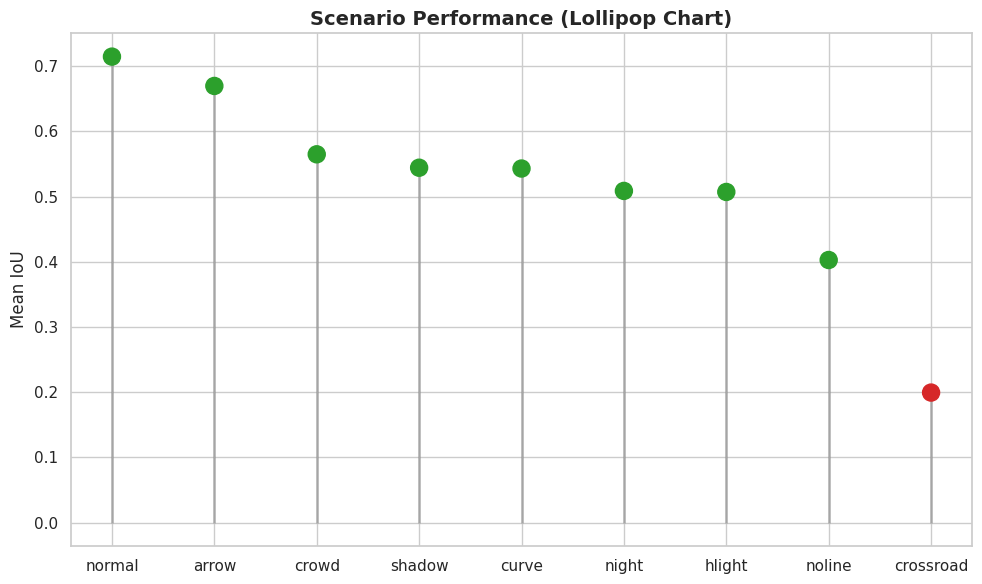

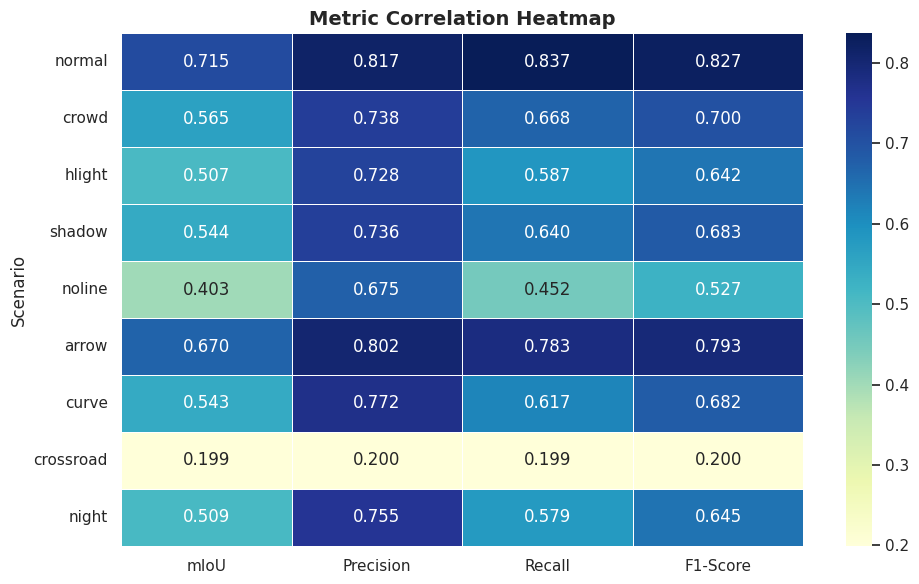

In [10]:
# ============================================================================
# CHART VISUALIZATION (Radar, Lollipop, Heatmap)
# ============================================================================

df = pd.DataFrame([
    {'Scenario': k, 'mIoU': v['mean_iou'], 'Pixel Acc': v['pixel_accuracy'], 
     'Precision': v['precision'], 'Recall': v['recall'], 'F1-Score': v['f1']}
    for k, v in scenario_results.items()
])

def save_charts():
    sns.set_theme(style="whitegrid")
    
    # 1. Lollipop Chart
    fig, ax = plt.subplots(figsize=(10, 6))
    df_sorted = df.sort_values('mIoU', ascending=False)
    ax.vlines(x=df_sorted['Scenario'], ymin=0, ymax=df_sorted['mIoU'], color='grey', alpha=0.5, linewidth=2)
    colors = ['#2ca02c' if x > 0.35 else '#ff7f0e' if x > 0.25 else '#d62728' for x in df_sorted['mIoU']]
    ax.scatter(x=df_sorted['Scenario'], y=df_sorted['mIoU'], s=150, color=colors, alpha=1, zorder=3)
    ax.set_title("Scenario Performance (Lollipop Chart)", fontsize=14, fontweight='bold')
    ax.set_ylabel("Mean IoU")
    plt.tight_layout()
    plt.savefig('lollipop_chart.png')
    plt.show()

    # 2. Heatmap
    fig, ax = plt.subplots(figsize=(10, 6))
    heatmap_data = df.set_index('Scenario')[['mIoU', 'Precision', 'Recall', 'F1-Score']]
    sns.heatmap(heatmap_data, annot=True, fmt=".3f", cmap="YlGnBu", linewidths=.5)
    ax.set_title("Metric Correlation Heatmap", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('heatmap_chart.png')
    plt.show()

save_charts()


🖼️ Processing Image: 00000.jpg...


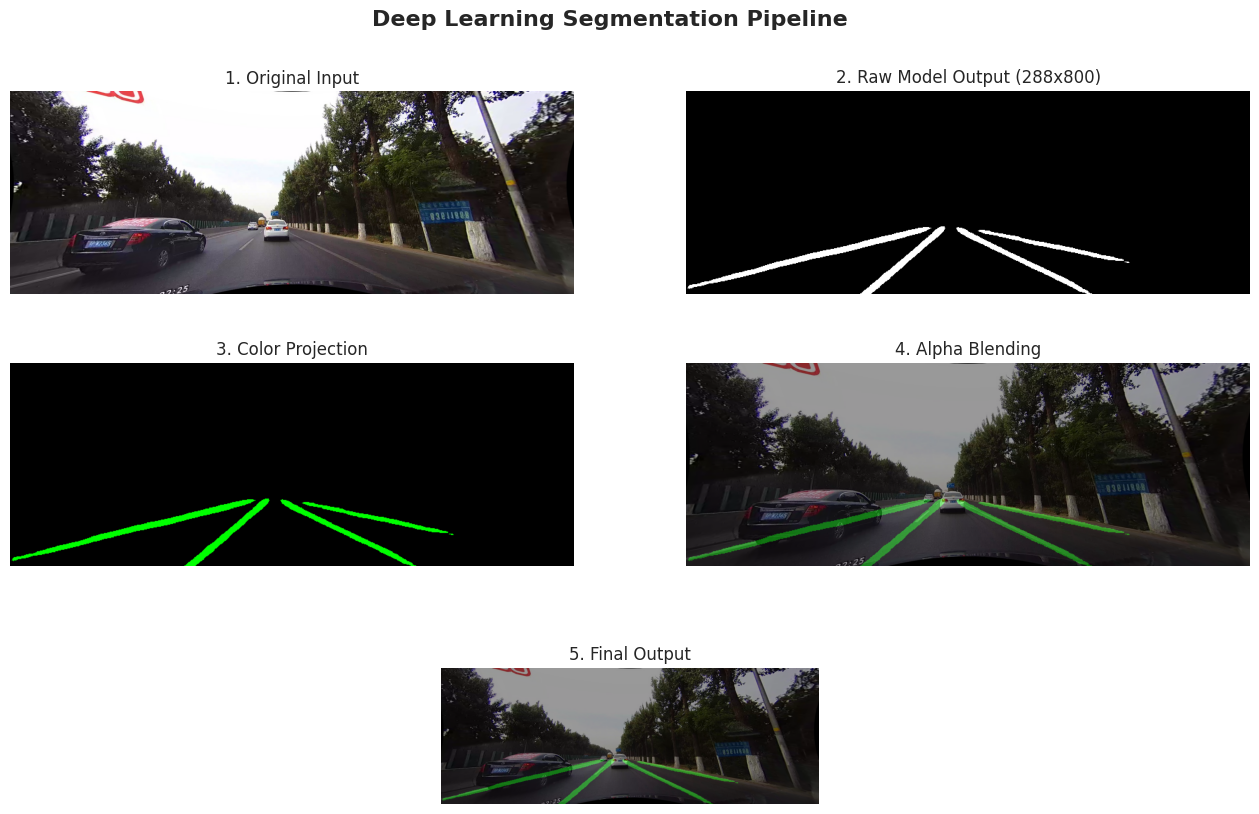

In [11]:
# ==========================================
# PIPELINE VISUALIZATION
# ==========================================
def visualize_pipeline(image_path):
    print(f"\n🖼️ Processing Image: {image_path.split('/')[-1]}...")
    
    # 1. Read Image
    image = cv2.imread(image_path)
    if image is None: return
    original_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    h, w = original_rgb.shape[:2]

    # 2. Preprocess & Inference
    input_tensor = val_transform(image=original_rgb)['image'].unsqueeze(0).to(Config.DEVICE)
    with torch.no_grad():
        out1 = model1(input_tensor)
        out2 = model2(input_tensor)
        ensemble = (out1 + out2) / 2
        raw_mask = torch.argmax(ensemble, dim=1).cpu().numpy()[0]

    # 3. Post-Processing
    # Resize mask to original image size
    mask_resized = cv2.resize(raw_mask.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST)
    
    # Create Color Mask (Green Lanes)
    color_mask = np.zeros_like(original_rgb)
    color_mask[mask_resized > 0] = [0, 255, 0] 

    # Blend
    blended = cv2.addWeighted(original_rgb, 0.6, color_mask, 0.4, 0)

    # 4. Plotting
    fig = plt.figure(figsize=(16, 10))
    plt.suptitle("Deep Learning Segmentation Pipeline", fontsize=16, fontweight='bold', y=0.95)

    # Custom Grid Layout
    ax1 = plt.subplot2grid((3, 2), (0, 0)); ax1.imshow(original_rgb); ax1.set_title("1. Original Input")
    ax1.axis('off')
    
    ax2 = plt.subplot2grid((3, 2), (0, 1)); ax2.imshow(raw_mask > 0, cmap='gray'); ax2.set_title("2. Raw Model Output (288x800)")
    ax2.axis('off')
    
    ax3 = plt.subplot2grid((3, 2), (1, 0)); ax3.imshow(color_mask); ax3.set_title("3. Color Projection")
    ax3.axis('off')
    
    ax4 = plt.subplot2grid((3, 2), (1, 1)); ax4.imshow(blended); ax4.set_title("4. Alpha Blending")
    ax4.axis('off')
    
    ax5 = plt.subplot2grid((3, 2), (2, 0), colspan=2); ax5.imshow(blended); ax5.set_title("5. Final Output")
    ax5.axis('off')
    
    # Center the final output
    pos = ax5.get_position()
    ax5.set_position([pos.x0 + pos.width*0.2, pos.y0, pos.width*0.6, pos.height])
    
    plt.show()

# Run on a sample test image
test_img = "/kaggle/input/culane/CULane/driver_161_90frame/driver_161_90frame/06030822_0756.MP4/00000.jpg"
visualize_pipeline(test_img)

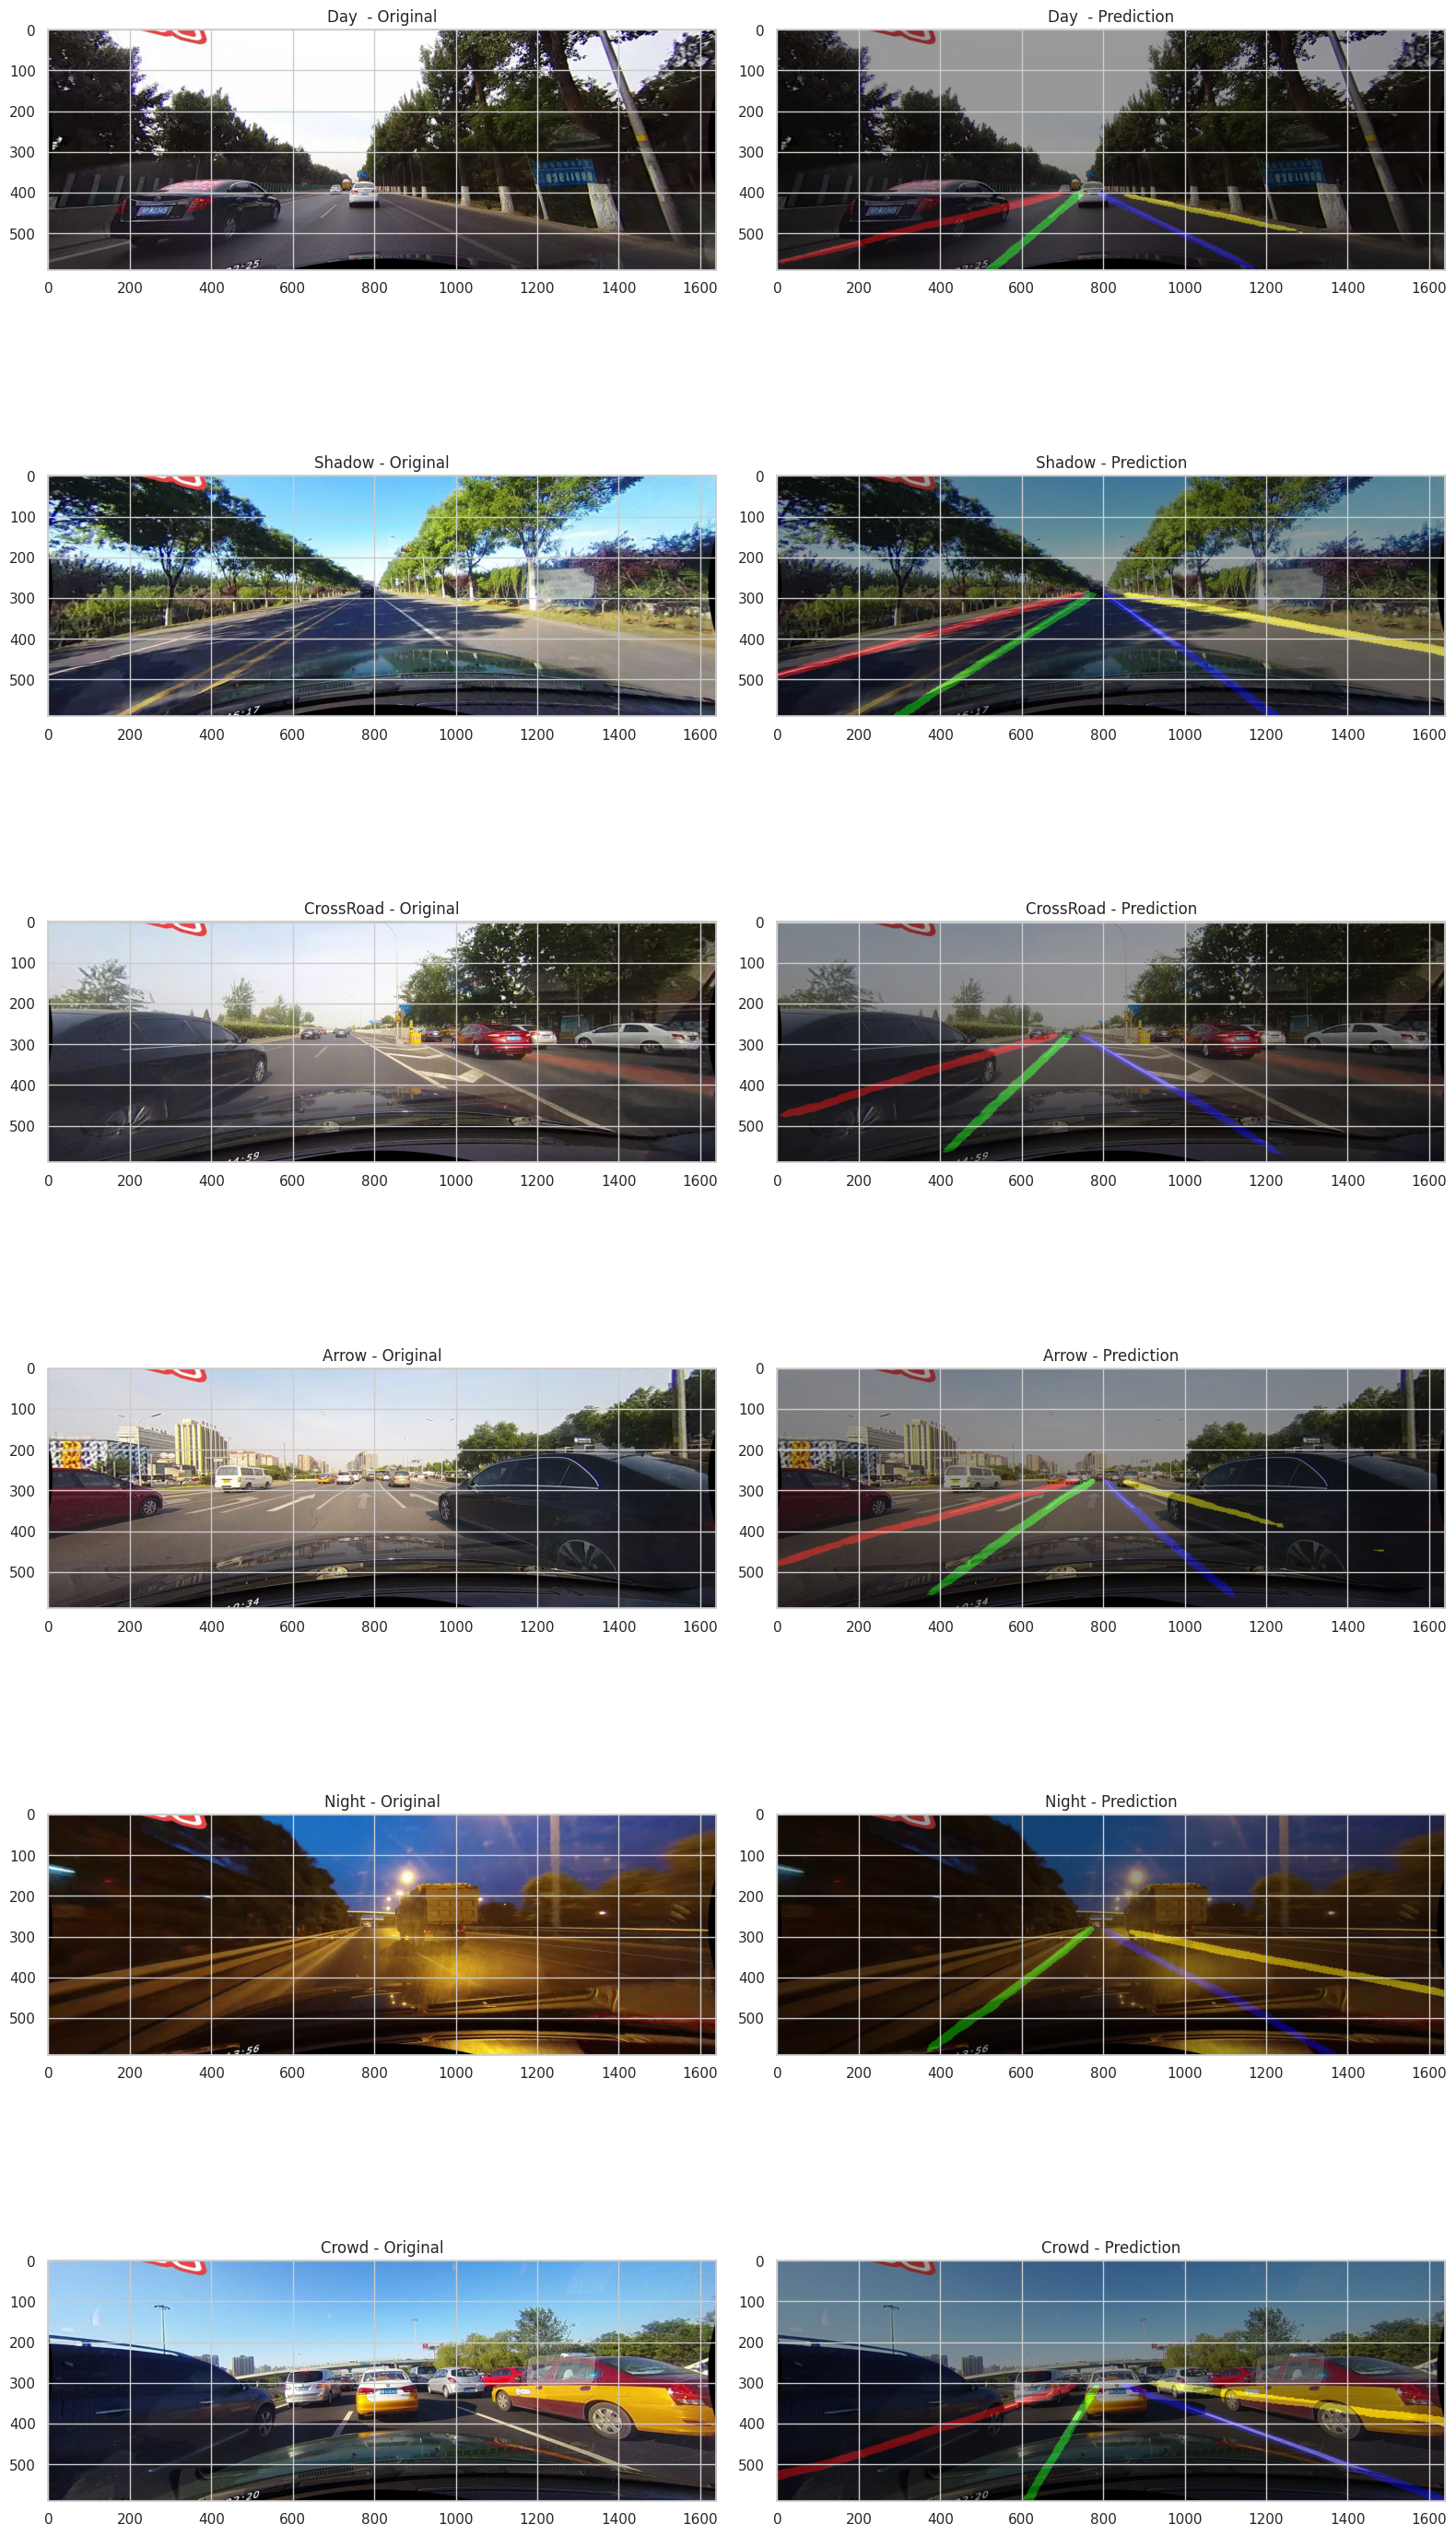

In [12]:
# ============================================================================
# VISUAL SUMMARY (Images)
# ============================================================================
def create_visual_summary(predictor):
    # Select specific difficult images
    test_images = {
        'Day ':"/kaggle/input/culane/CULane/driver_161_90frame/driver_161_90frame/06030822_0756.MP4/00000.jpg",
        'Shadow':"/kaggle/input/culane/CULane/driver_23_30frame/driver_23_30frame/05151646_0421.MP4/00030.jpg",
        'CrossRoad':"/kaggle/input/culane/CULane/video_example/05081544_0305/05081544_0305-000004.jpg",
        'Arrow':"/kaggle/input/culane/CULane/driver_37_30frame/driver_37_30frame/05181608_0235.MP4/04500.jpg",
        'Night': "/kaggle/input/culane/CULane/driver_193_90frame/driver_193_90frame/06042013_0512.MP4/00090.jpg",
        'Crowd':"/kaggle/input/culane/CULane/driver_23_30frame/driver_23_30frame/05160732_0448.MP4/00435.jpg"
    }
    
    colors = [[0,0,0], [255,0,0], [0,255,0], [0,0,255], [255,255,0], [255,0,255], [0,255,255], [255,128,0], [128,0,255]]
    
    fig, axes = plt.subplots(len(test_images), 2, figsize=(16, 5 * len(test_images)))
    if len(test_images) == 1: axes = np.expand_dims(axes, axis=0)

    for idx, (name, path) in enumerate(test_images.items()):
        image = cv2.imread(path)
        if image is None: continue
        original = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Predict
        transformed = val_transform(image=original, mask=np.zeros((image.shape[0], image.shape[1])))
        input_tensor = transformed['image'].unsqueeze(0).to(config.DEVICE)
        
        preds, _ = predictor.predict(input_tensor)
        pred_mask = preds.cpu().numpy()[0]
        
        # Resize and Overlay
        pred_mask_resized = cv2.resize(pred_mask.astype(np.uint8), (original.shape[1], original.shape[0]), interpolation=cv2.INTER_NEAREST)
        color_mask = np.zeros_like(original)
        for lane_id in range(1, 9):
            color_mask[pred_mask_resized == lane_id] = colors[lane_id]
        
        overlay = cv2.addWeighted(original, 0.6, color_mask, 0.4, 0)
        
        axes[idx, 0].imshow(original)
        axes[idx, 0].set_title(f'{name} - Original')
        axes[idx, 1].imshow(overlay)
        axes[idx, 1].set_title(f'{name} - Prediction')
        
    plt.tight_layout()
    plt.savefig('visual_summary.png')
    plt.show()

create_visual_summary(ensemble_predictor)

In [13]:
def calculate_fps(model, input_size=(288, 800)):
    model.eval()
    dummy_input = torch.randn(1, 3, *input_size).to(config.DEVICE)
    
    # Warmup
    for _ in range(10): _ = model(dummy_input)
    
    start = torch.cuda.Event(enable_timing=True)
    end = torch.cuda.Event(enable_timing=True)
    
    start.record()
    for _ in range(100): _ = model(dummy_input)
    end.record()
    torch.cuda.synchronize()
    
    total_time_ms = start.elapsed_time(end)
    return 100 / (total_time_ms / 1000)

fps = calculate_fps(model1) 
# Testing single model speed (Ensemble will be ~half)
print(f"\n🚀 Model Speed: {fps:.1f} FPS")

fps = calculate_fps(model2) 
# Testing single model speed (Ensemble will be ~half)
print(f"\n🚀 Shadow & Night Model Speed: {fps:.1f} FPS")


🚀 Model Speed: 33.4 FPS

🚀 Shadow & Night Model Speed: 32.9 FPS


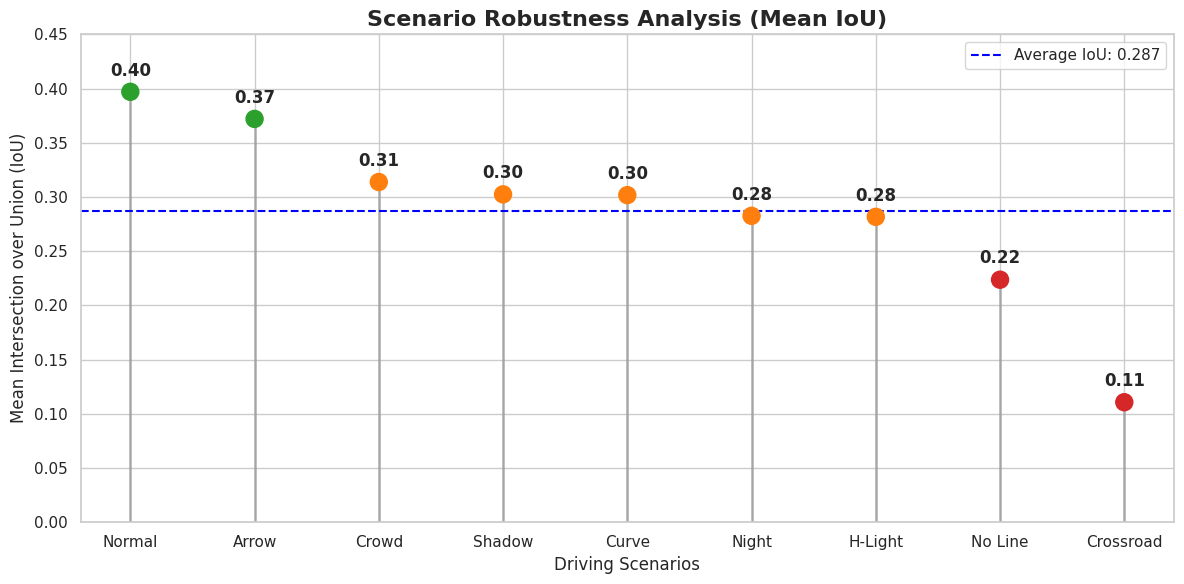

In [14]:
# Data from your evaluation results
data = {
    'Scenario': ['Normal', 'Crowd', 'H-Light', 'Shadow', 'No Line', 'Arrow', 'Curve', 'Crossroad', 'Night'],
    'mIoU': [0.3970, 0.3138, 0.2817, 0.3024, 0.2237, 0.3720, 0.3017, 0.1107, 0.2826],
    'Pixel Acc': [0.9836, 0.9749, 0.9728, 0.9763, 0.9676, 0.9808, 0.9783, 0.9966, 0.9778]
}
df = pd.DataFrame(data)
sns.set_theme(style="whitegrid")

# Create a Professional Lollipop Chart
fig, ax = plt.subplots(figsize=(12, 6))
df_sorted = df.sort_values('mIoU', ascending=False)

# Draw lines
ax.vlines(x=df_sorted['Scenario'], ymin=0, ymax=df_sorted['mIoU'], color='grey', alpha=0.5, linewidth=2)

# Draw points (Color coded by performance)
colors = ['#2ca02c' if x > 0.35 else '#ff7f0e' if x > 0.25 else '#d62728' for x in df_sorted['mIoU']]
ax.scatter(x=df_sorted['Scenario'], y=df_sorted['mIoU'], s=150, color=colors, zorder=3)

# Add values
for i, txt in enumerate(df_sorted['mIoU']):
    ax.annotate(f"{txt:.2f}", (df_sorted['Scenario'].iloc[i], df_sorted['mIoU'].iloc[i]+0.015),
                ha='center', fontweight='bold')

plt.title("Scenario Robustness Analysis (Mean IoU)", fontsize=16, fontweight='bold')
plt.ylabel("Mean Intersection over Union (IoU)")
plt.xlabel("Driving Scenarios")
plt.ylim(0, 0.45)
plt.axhline(y=df['mIoU'].mean(), color='blue', linestyle='--', label=f"Average IoU: {df['mIoU'].mean():.3f}")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
!pip install -q streamlit pyngrok

In [24]:
%%writefile app.py
import streamlit as st
import torch
import cv2
import numpy as np
import segmentation_models_pytorch as smp
import albumentations as A
from albumentations.pytorch import ToTensorV2
from PIL import Image
import os
import signal
import time
import plotly.graph_objects as go
import pandas as pd
import io
from datetime import datetime

# ==========================================
# CONFIGURATION
# ==========================================
class Config:
    IMG_HEIGHT = 288
    IMG_WIDTH = 800
    NUM_CLASSES = 9
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    
    LANE_COLORS = {
        1: [255, 0, 0],      # Red
        2: [0, 255, 0],      # Green
        3: [0, 0, 255],      # Blue
        4: [255, 255, 0],    # Yellow
        5: [255, 0, 255],    # Magenta
        6: [0, 255, 255],    # Cyan
        7: [255, 128, 0],    # Orange
        8: [128, 0, 255]     # Purple
    }
    
    LANE_NAMES = {
        1: "Left Outer",
        2: "Left Inner",
        3: "Right Inner",
        4: "Right Outer",
        5: "Emergency Lane",
        6: "Bike Lane",
        7: "Turning Lane",
        8: "Center Lane"
    }

config = Config()

# ==========================================
# LOAD MODELS
# ==========================================
@st.cache_resource
def load_ensemble_model():
    try:
        model1 = smp.DeepLabV3Plus(
            encoder_name="resnet50",
            encoder_weights=None,
            in_channels=3,
            classes=config.NUM_CLASSES
        )
        model1.load_state_dict(torch.load(
            "/kaggle/input/culane-model/pytorch/default/1/best_deeplabv3plus_culane.pth",
            map_location=config.DEVICE
        )["model_state_dict"])
        model1.to(config.DEVICE).eval()

        model2 = smp.DeepLabV3Plus(
            encoder_name="resnet50",
            encoder_weights=None,
            in_channels=3,
            classes=config.NUM_CLASSES
        )
        model2.load_state_dict(torch.load(
            "/kaggle/input/trainned-model-culane/pytorch/default/1/best_shadow_night_model.pth",
            map_location=config.DEVICE
        )["model_state_dict"])
        model2.to(config.DEVICE).eval()
        
        return model1, model2, True
    except Exception as e:
        st.error(f"Model loading failed: {str(e)}")
        return None, None, False

# ==========================================
# PREPROCESS
# ==========================================
def preprocess_image(image):
    image_np = np.array(image)
    transform = A.Compose([
        A.Resize(config.IMG_HEIGHT, config.IMG_WIDTH),
        A.Normalize(mean=(0.485, 0.456, 0.406),
                    std=(0.229, 0.224, 0.225)),
        ToTensorV2()
    ])
    tensor = transform(image=image_np)["image"]
    return tensor.unsqueeze(0).to(config.DEVICE), image_np

# ==========================================
# METRICS & VISUALIZATION
# ==========================================
def calculate_metrics(mask):
    total_pixels = mask.size
    lane_pixels = np.sum(mask > 0)
    unique_lanes = np.unique(mask[mask > 0])
    lanes_detected = len(unique_lanes)
    coverage = (lane_pixels / total_pixels) * 100
    
    # Per lane statistics
    lane_stats = {}
    for lane_id in unique_lanes:
        lane_mask = (mask == lane_id)
        lane_pixel_count = np.sum(lane_mask)
        lane_coverage = (lane_pixel_count / total_pixels) * 100
        lane_stats[int(lane_id)] = {
            'pixels': lane_pixel_count,
            'coverage': lane_coverage,
            'name': config.LANE_NAMES.get(lane_id, f"Lane {lane_id}")
        }
    
    return lanes_detected, coverage, lane_pixels, lane_stats

def create_visualization_figure(lane_stats):
    if not lane_stats:
        return None
    
    lane_ids = list(lane_stats.keys())
    lane_names = [lane_stats[id]['name'] for id in lane_ids]
    coverages = [lane_stats[id]['coverage'] for id in lane_ids]
    
    fig = go.Figure(data=[
        go.Bar(
            x=lane_names,
            y=coverages,
            marker_color=[f'rgb{tuple(config.LANE_COLORS[id])}' for id in lane_ids],
            text=[f'{c:.1f}%' for c in coverages],
            textposition='auto',
        )
    ])
    
    fig.update_layout(
        title="Lane Coverage Distribution",
        xaxis_title="Lane Type",
        yaxis_title="Coverage (%)",
        plot_bgcolor='rgba(10, 10, 30, 0.8)',
        paper_bgcolor='rgba(10, 10, 30, 0.8)',
        font_color='#a5f3fc',
        height=400
    )
    
    return fig

# ==========================================
# SIDEBAR FUNCTIONS
# ==========================================
def create_sidebar():
    with st.sidebar:
        st.markdown("""
        <div style="text-align: center; padding: 10px; background: linear-gradient(135deg, #4f46e5, #9333ea); border-radius: 10px; margin-bottom: 20px;">
            <h3 style="color: white; margin: 0;">🎛️ CONTROL PANEL</h3>
        </div>
        """, unsafe_allow_html=True)
        
        # Model Info
        with st.expander("🔧 Model Information", expanded=True):
            st.info(f"""
            **Model:** DeepLabV3+ Ensemble
            **Encoder:** ResNet50
            **Classes:** {config.NUM_CLASSES}
            **Device:** {str(config.DEVICE).upper()}
            """)
        
        # Visualization Settings
        with st.expander("🎨 Visualization Settings", expanded=True):
            alpha = st.slider("Overlay Transparency", 0.0, 1.0, 0.4, 0.05)
            show_mask = st.checkbox("Show Raw Mask", value=False)
            brightness = st.slider("Brightness Adjustment", 0.5, 1.5, 1.0, 0.1)
            
        # File Upload
        uploaded_file = st.file_uploader(
            "📁 Upload Road Image",
            type=["jpg", "png", "jpeg", "bmp"],
            help="Upload a clear image of road for lane detection"
        )
        
        # Advanced Settings
        with st.expander("⚙️ Advanced Settings"):
            confidence_threshold = st.slider(
                "Confidence Threshold", 0.0, 1.0, 0.5, 0.05
            )
            smoothing = st.checkbox("Apply Smoothing", value=True)
            
        # System Info
        with st.expander("📊 System Status"):
            st.metric("GPU Available", "✅" if torch.cuda.is_available() else "❌")
            st.metric("Memory Usage", f"{torch.cuda.memory_allocated()/1e9:.1f} GB" 
                     if torch.cuda.is_available() else "CPU Mode")
        
        return uploaded_file, alpha, show_mask, brightness, confidence_threshold, smoothing

# ==========================================
# MAIN DASHBOARD
# ==========================================
def create_dashboard():
    # Header with Logo
    col1, col2, col3 = st.columns([0.1, 0.8, 0.1])
    with col2:
        st.markdown("""
        <div style="text-align: center;">
            <h1 style="background: linear-gradient(90deg, #22c55e, #3b82f6, #ec4899); 
                      -webkit-background-clip: text;
                      -webkit-text-fill-color: transparent;
                      font-size: 3em;
                      margin-bottom: 0;">
                🚗 Intelligent Lane Segmentation
            </h1>
            <p style="color: #a5f3fc; font-size: 1.2em;">
                Advanced AI for Shadow & Night Robust Lane Detection
            </p>
        </div>
        """, unsafe_allow_html=True)
    
    st.divider()
    
    # Stats Overview
    st.markdown("### 📈 Performance Overview")
    col1, col2, col3, col4 = st.columns(4)
    
    with col1:
        st.metric("Models Loaded", "2", "Ensemble")
    with col2:
        st.metric("Input Resolution", f"{config.IMG_HEIGHT}x{config.IMG_WIDTH}")
    with col3:
        st.metric("Lane Classes", config.NUM_CLASSES)
    with col4:
        gpu_status = "Active" if torch.cuda.is_available() else "CPU"
        st.metric("Inference Device", gpu_status)

# ==========================================
# RESULT DISPLAY
# ==========================================
def display_results(original_img, overlay_mask, mask, lane_stats, alpha, brightness):
    # Create tabs for different views
    tab1, tab2, tab3, tab4 = st.tabs(["🎨 Overlay View", "📊 Analysis", "🔍 Details", "📈 Statistics"])
    
    with tab1:
        col1, col2 = st.columns(2)
        with col1:
            st.markdown("### Original Image")
            st.image(original_img, use_container_width=True, caption="Input Road Image")
        with col2:
            st.markdown("### Detected Lanes")
            st.image(overlay_mask, use_container_width=True, caption=f"Lane Detection (α={alpha})")
    
    with tab2:
        # Create a 3-column layout for metrics
        m1, m2, m3 = st.columns(3)
        
        lanes_detected, coverage, lane_pixels, _ = calculate_metrics(mask)
        
        with m1:
            st.markdown(f"""
            <div class='metric-card'>
                <h3>🚦 Lanes Detected</h3>
                <h1 style="color: #22c55e; font-size: 3em;">{lanes_detected}</h1>
                <p>Total identified lanes</p>
            </div>
            """, unsafe_allow_html=True)
        
        with m2:
            st.markdown(f"""
            <div class='metric-card'>
                <h3>📏 Coverage Area</h3>
                <h1 style="color: #3b82f6; font-size: 3em;">{coverage:.1f}%</h1>
                <p>Of total image area</p>
            </div>
            """, unsafe_allow_html=True)
        
        with m3:
            st.markdown(f"""
            <div class='metric-card'>
                <h3>🖼️ Lane Pixels</h3>
                <h1 style="color: #ec4899; font-size: 3em;">{lane_pixels:,}</h1>
                <p>Detected lane pixels</p>
            </div>
            """, unsafe_allow_html=True)
        
        # Lane distribution visualization
        fig = create_visualization_figure(lane_stats)
        if fig:
            st.plotly_chart(fig, use_container_width=True)
    
    with tab3:
        # Detailed lane information
        st.markdown("### 🎯 Lane-by-Lane Details")
        if lane_stats:
            for lane_id, stats in lane_stats.items():
                col1, col2, col3 = st.columns([0.2, 0.6, 0.2])
                with col1:
                    color = config.LANE_COLORS.get(lane_id, [255, 255, 255])
                    st.markdown(
                        f"<div style='width: 30px; height: 30px; background-color: rgb{tuple(color)}; border-radius: 5px;'></div>",
                        unsafe_allow_html=True
                    )
                with col2:
                    st.write(f"**{stats['name']}**")
                    progress = stats['coverage'] / 100
                    st.progress(progress, text=f"Coverage: {stats['coverage']:.1f}%")
                with col3:
                    st.write(f"Pixels: {stats['pixels']:,}")
        
        # Mask display
        if st.checkbox("Show Raw Segmentation Mask"):
            st.image(mask, use_container_width=True, caption="Raw Segmentation Mask", clamp=True)
    
    with tab4:
        # Statistical analysis
        st.markdown("### 📊 Statistical Analysis")
        
        # Create DataFrame for statistics
        if lane_stats:
            df = pd.DataFrame.from_dict(lane_stats, orient='index')
            df = df[['name', 'coverage', 'pixels']]
            df = df.sort_values('coverage', ascending=False)
            
            col1, col2 = st.columns(2)
            with col1:
                st.dataframe(
                    df.style.background_gradient(subset=['coverage'], cmap='viridis'),
                    use_container_width=True
                )
            
            with col2:
                # Pie chart for lane distribution
                fig_pie = go.Figure(data=[go.Pie(
                    labels=df['name'],
                    values=df['pixels'],
                    hole=.3,
                    marker_colors=[f'rgb{tuple(config.LANE_COLORS.get(idx, [128,128,128]))}' 
                                  for idx in lane_stats.keys()]
                )])
                fig_pie.update_layout(
                    title="Lane Pixel Distribution",
                    plot_bgcolor='rgba(10, 10, 30, 0.8)',
                    paper_bgcolor='rgba(10, 10, 30, 0.8)',
                    font_color='#a5f3fc'
                )
                st.plotly_chart(fig_pie, use_container_width=True)

# ==========================================
# ENHANCED CSS STYLING
# ==========================================
def apply_custom_styles():
    st.markdown("""
    <style>
    /* Main background */
    .stApp {
        background: linear-gradient(135deg, #0f172a 0%, #1e293b 50%, #0f172a 100%);
    }
    
    /* Metric cards */
    .metric-card {
        background: rgba(30, 41, 59, 0.7);
        padding: 1.5rem;
        border-radius: 15px;
        border-left: 5px solid #22c55e;
        box-shadow: 0 4px 15px rgba(0, 0, 0, 0.3);
        transition: transform 0.3s ease;
        text-align: center;
    }
    
    .metric-card:hover {
        transform: translateY(-5px);
        box-shadow: 0 8px 25px rgba(34, 197, 94, 0.2);
    }
    
    /* Sidebar styling */
    .css-1d391kg {
        background: rgba(15, 23, 42, 0.9) !important;
    }
    
    /* Button styling */
    .stButton > button {
        background: linear-gradient(135deg, #4f46e5 0%, #9333ea 100%);
        color: white;
        font-weight: 600;
        padding: 0.75rem 2rem;
        border-radius: 10px;
        border: none;
        transition: all 0.3s ease;
        width: 100%;
    }
    
    .stButton > button:hover {
        transform: scale(1.05);
        box-shadow: 0 5px 20px rgba(147, 51, 234, 0.4);
    }
    
    /* Progress bar */
    .stProgress > div > div > div {
        background: linear-gradient(90deg, #22c55e, #3b82f6, #ec4899);
    }
    
    /* Tab styling */
    .stTabs [data-baseweb="tab-list"] {
        gap: 2rem;
        background-color: rgba(30, 41, 59, 0.7);
        padding: 10px;
        border-radius: 10px;
    }
    
    .stTabs [data-baseweb="tab"] {
        height: 50px;
        white-space: pre-wrap;
        background-color: rgba(30, 41, 59, 0.5);
        border-radius: 5px;
        gap: 1rem;
        padding: 10px 20px;
    }
    
    /* Expander styling */
    .streamlit-expanderHeader {
        background-color: rgba(30, 41, 59, 0.7);
        border-radius: 10px;
        border-left: 4px solid #3b82f6;
    }
    
    /* Footer */
    .footer {
        position: fixed;
        bottom: 0;
        width: 100%;
        background: rgba(15, 23, 42, 0.9);
        text-align: center;
        padding: 10px;
        color: #a5f3fc;
        font-size: 0.9em;
    }
    
    /* Legend items */
    .legend-item {
        display: flex;
        align-items: center;
        gap: 10px;
        padding: 8px 12px;
        background: rgba(30, 41, 59, 0.5);
        border-radius: 8px;
        margin-bottom: 8px;
        transition: all 0.3s ease;
    }
    
    .legend-item:hover {
        background: rgba(59, 130, 246, 0.2);
        transform: translateX(5px);
    }
    </style>
    """, unsafe_allow_html=True)

# ==========================================
# MAIN APP
# ==========================================
def main():
    # Page configuration
    st.set_page_config(
        page_title="Lane Detection AI Dashboard",
        page_icon="🚗",
        layout="wide",
        initial_sidebar_state="expanded"
    )
    
    # Apply custom styles
    apply_custom_styles()
    
    # Initialize session state for storing results
    if 'detection_results' not in st.session_state:
        st.session_state.detection_results = None
    if 'mask_image' not in st.session_state:
        st.session_state.mask_image = None
    if 'report_data' not in st.session_state:
        st.session_state.report_data = None
    
    # Load models
    with st.spinner("🚀 Loading AI Models..."):
        model1, model2, models_loaded = load_ensemble_model()
    
    if not models_loaded:
        st.error("Failed to load models. Please check model paths.")
        return
    
    # Create main dashboard
    create_dashboard()
    
    # Sidebar controls
    uploaded_file, alpha, show_mask, brightness, confidence_threshold, smoothing = create_sidebar()
    
    # Run button in sidebar
    st.sidebar.divider()
    run_button = st.sidebar.button("🚀 **RUN LANE DETECTION**", type="primary", use_container_width=True)
    
    # Emergency stop button
    if st.sidebar.button("⛔ **EMERGENCY STOP**", type="secondary", use_container_width=True):
        st.error("Application stopped by user.")
        os.kill(os.getpid(), signal.SIGTERM)
    
    # Process image if uploaded and run button clicked
    if uploaded_file and run_button:
        try:
            # Load and process image
            image = Image.open(uploaded_file).convert("RGB")
            
            # Create progress container
            progress_container = st.empty()
            with progress_container.container():
                st.markdown("### 🔄 Processing Pipeline")
                
                # Progress steps
                progress_bar = st.progress(0)
                status_text = st.empty()
                
                status_text.text("📥 Loading image...")
                input_tensor, original_np = preprocess_image(image)
                progress_bar.progress(25)
                
                status_text.text("🧠 Running inference...")
                with torch.no_grad():
                    out = (model1(input_tensor) + model2(input_tensor)) / 2
                    mask = torch.argmax(out, dim=1).cpu().numpy()[0]
                progress_bar.progress(60)
                
                status_text.text("🎨 Generating visualization...")
                # Resize mask to original dimensions
                mask_resized = cv2.resize(
                    mask.astype(np.uint8),
                    (original_np.shape[1], original_np.shape[0]),
                    interpolation=cv2.INTER_NEAREST
                )
                
                # Create colored mask
                color_mask = np.zeros_like(original_np)
                for k, v in config.LANE_COLORS.items():
                    color_mask[mask_resized == k] = v
                
                # Apply overlay with alpha blending
                overlay = cv2.addWeighted(
                    original_np, 1 - alpha, color_mask, alpha, 0
                )
                
                # Adjust brightness if needed
                if brightness != 1.0:
                    overlay = np.clip(overlay * brightness, 0, 255).astype(np.uint8)
                
                progress_bar.progress(85)
                
                status_text.text("📊 Calculating metrics...")
                lanes_detected, coverage, lane_pixels, lane_stats = calculate_metrics(mask_resized)
                progress_bar.progress(100)
                
                # Store results in session state
                st.session_state.detection_results = {
                    'original_image': image,
                    'overlay_image': overlay,
                    'mask': mask_resized,
                    'lane_stats': lane_stats,
                    'alpha': alpha,
                    'brightness': brightness,
                    'lanes_detected': lanes_detected,
                    'coverage': coverage,
                    'lane_pixels': lane_pixels
                }
                
                # Prepare mask for download
                mask_display = (mask_resized * 255).astype(np.uint8)
                st.session_state.mask_image = Image.fromarray(mask_display)
                
                # Prepare report data
                report_data = {
                    'timestamp': datetime.now().strftime('%Y-%m-%d %H:%M:%S'),
                    'image_name': uploaded_file.name,
                    'image_dimensions': f"{original_np.shape[1]}x{original_np.shape[0]}",
                    'lanes_detected': lanes_detected,
                    'coverage_percentage': round(coverage, 2),
                    'total_lane_pixels': lane_pixels
                }
                
                # Add lane-specific data
                for lane_id, stats in lane_stats.items():
                    report_data[f'lane_{lane_id}_name'] = stats['name']
                    report_data[f'lane_{lane_id}_pixels'] = stats['pixels']
                    report_data[f'lane_{lane_id}_coverage'] = round(stats['coverage'], 2)
                
                st.session_state.report_data = report_data
                
                status_text.text("✅ Processing complete!")
                time.sleep(0.5)
            
            # Clear progress container
            progress_container.empty()
            
            # Display results from session state
            results = st.session_state.detection_results
            display_results(
                results['original_image'], 
                results['overlay_image'], 
                results['mask'], 
                results['lane_stats'], 
                results['alpha'], 
                results['brightness']
            )
            
            # Professional success notification
            st.markdown("---")
            success_col1, success_col2, success_col3 = st.columns([0.1, 0.8, 0.1])
            with success_col2:
                st.markdown("""
                <div style="background: linear-gradient(135deg, rgba(34, 197, 94, 0.1), rgba(59, 130, 246, 0.1)); 
                            padding: 1.5rem; border-radius: 10px; border-left: 4px solid #22c55e; text-align: center;">
                    <h4 style="color: #22c55e; margin-bottom: 0.5rem;">✅ Analysis Complete</h4>
                    <p style="color: #a5f3fc; margin-bottom: 0;">
                        Successfully processed <strong>{}</strong> with detection of <strong>{} lanes</strong> 
                        covering <strong>{:.1f}%</strong> of the image area.
                    </p>
                </div>
                """.format(uploaded_file.name, results['lanes_detected'], results['coverage']), unsafe_allow_html=True)
            
            # Legend
            with st.expander("🎨 **Color Legend**", expanded=True):
                cols = st.columns(4)
                for idx, (lane_id, color) in enumerate(config.LANE_COLORS.items()):
                    with cols[idx % 4]:
                        lane_name = config.LANE_NAMES.get(lane_id, f"Lane {lane_id}")
                        st.markdown(f"""
                        <div style="display: flex; align-items: center; gap: 8px; margin-bottom: 8px;">
                            <div style="width: 20px; height: 20px; background-color: rgb{tuple(color)}; border-radius: 4px;"></div>
                            <span style="color: #a5f3fc;">{lane_name}</span>
                        </div>
                        """, unsafe_allow_html=True)
            
            # Export options - FIXED: Always show download buttons after detection
            if st.session_state.mask_image and st.session_state.report_data:
                st.sidebar.divider()
                st.sidebar.markdown("### 💾 Export Results")
                
                # Download mask button
                mask_bytes = io.BytesIO()
                st.session_state.mask_image.save(mask_bytes, format='PNG')
                
                col1, col2 = st.sidebar.columns(2)
                with col1:
                    st.sidebar.download_button(
                        label="📥 Download Mask",
                        data=mask_bytes.getvalue(),
                        file_name=f"lane_mask_{datetime.now().strftime('%Y%m%d_%H%M%S')}.png",
                        mime="image/png",
                        key="download_mask"
                    )
                
                with col2:
                    # Create CSV report
                    report_df = pd.DataFrame([st.session_state.report_data])
                    csv_data = report_df.to_csv(index=False)
                    
                    st.sidebar.download_button(
                        label="📊 Save Report",
                        data=csv_data,
                        file_name=f"lane_report_{datetime.now().strftime('%Y%m%d_%H%M%S')}.csv",
                        mime="text/csv",
                        key="download_report"
                    )
                    
        except Exception as e:
            st.error(f"❌ Error during processing: {str(e)}")
            st.exception(e)
    
    elif not uploaded_file:
        # Welcome/Instruction screen
        st.markdown("""
        <div style="text-align: center; padding: 4rem; background: rgba(30, 41, 59, 0.5); border-radius: 20px; margin: 2rem 0;">
            <h2 style="color: #22c55e; margin-bottom: 1rem;">🚦 Welcome to Lane Detection AI</h2>
            <p style="color: #a5f3fc; font-size: 1.1rem; margin-bottom: 2rem;">
                Upload a road image to start lane detection analysis
            </p>
            <div style="display: flex; justify-content: center; gap: 1rem; margin-top: 2rem;">
                <div style="background: rgba(34, 197, 94, 0.1); padding: 1rem; border-radius: 10px; width: 200px;">
                    <h4>📁 Upload</h4>
                    <p>Upload road image via sidebar</p>
                </div>
                <div style="background: rgba(59, 130, 246, 0.1); padding: 1rem; border-radius: 10px; width: 200px;">
                    <h4>⚙️ Configure</h4>
                    <p>Adjust detection settings</p>
                </div>
                <div style="background: rgba(236, 72, 153, 0.1); padding: 1rem; border-radius: 10px; width: 200px;">
                    <h4>🚀 Analyze</h4>
                    <p>Run lane detection</p>
                </div>
            </div>
        </div>
        """, unsafe_allow_html=True)
    
    # Footer
    st.markdown("""
    <div class="footer">
        <p>🚗 Lane Detection AI Dashboard • Powered by DeepLabV3+ Ensemble • Made with Streamlit</p>
    </div>
    """, unsafe_allow_html=True)
# ==========================================
# ENTRY POINT
# ==========================================
if __name__ == "__main__":
    main()

Overwriting app.py


In [28]:
from pyngrok import ngrok

# 1. Setup Token
ngrok.set_auth_token("38T5oxq7hD9Mt4MAMmAj3dUKHtH_5skV63qqpe3TBSjtMcpCC")

# 2. Kill previous tunnels (if re-running)
ngrok.kill()

# 3. Open Tunnel to Port 8501
public_url = ngrok.connect(8501).public_url
print(f"🚀 YOUR APP IS LIVE AT: {public_url}")

# 4. Run Streamlit
!streamlit run app.py >/dev/null

🚀 YOUR APP IS LIVE AT: https://workaday-tora-antheridial.ngrok-free.dev
^C

Aborted!
